# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [ ]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [ ]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

# Gate C — gate-current-sanity-check (runs 0–3)

First-session liveness on the provided hardwired configuration (`device-init/gate-current-sanity-check.md`; no designated references — strict isolation, traces judged on their own terms). Four legs at base T (1.18 K), B = 0, Si = 0: TG 0→±3 V and BG 0→±4.5 V (the committed card limits), other gate parked, 251 pts/leg, nplci 10, I_bias = 5 nA (0.5 V / 100 MΩ). Raw per-leg traces below, then the verdict.


C:\Users\DGG\AppData\Local\Temp\ipykernel_5228\3410244172.py:14: UserWarning: column 'k_2400_tg_volt' appears at indices [1, 4]; returning index 1 (the planned/setpoint instance) — col_at(idx) selects the others
  V = run.col(xname)
C:\Users\DGG\AppData\Local\Temp\ipykernel_5228\3410244172.py:14: UserWarning: column 'k_2400_bg_volt' appears at indices [1, 6]; returning index 1 (the planned/setpoint instance) — col_at(idx) selects the others
  V = run.col(xname)


run 0 (TG 0→+3 V): rows 251/251, max|I_tg| 47 pA, max|I_bg| 108 pA, I_drain 5.00 nA, sr1 R [56, 1670] Ohm
run 1 (TG 0→−3 V): rows 251/251, max|I_tg| 36 pA, max|I_bg| 108 pA, I_drain 4.99 nA, sr1 R [58, 1645] Ohm
run 2 (BG 0→+4.5 V): rows 251/251, max|I_tg| 38 pA, max|I_bg| 107 pA, I_drain 4.99 nA, sr1 R [23, 2072] Ohm
run 3 (BG 0→−4.5 V): rows 251/251, max|I_tg| 37 pA, max|I_bg| 112 pA, I_drain 4.99 nA, sr1 R [31, 1550] Ohm


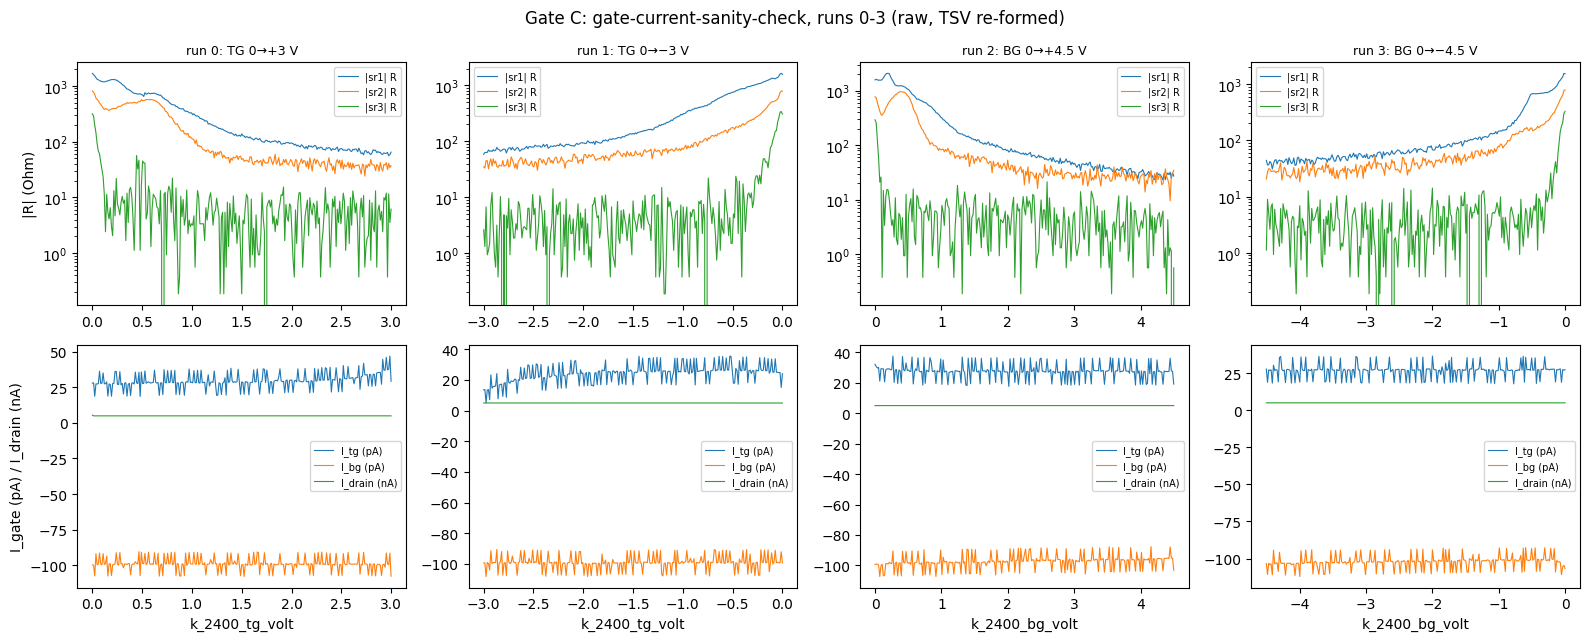

In [1]:
# Gate C raw traces — runs 0-3, re-formed from TSV (plot.png is the monitor, not the measurement)
import numpy as np
import matplotlib.pyplot as plt
from hera.analysis import open_run

I_BIAS = 5e-9
SR0_GAIN = -1e6
LEGS = {0: "TG 0→+3 V", 1: "TG 0→−3 V", 2: "BG 0→+4.5 V", 3: "BG 0→−4.5 V"}

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for i, (rid, label) in enumerate(LEGS.items()):
    run = open_run(f"data/{rid}")
    xname = "k_2400_tg_volt" if rid < 2 else "k_2400_bg_volt"
    V = run.col(xname)
    ax = axes[0, i]
    for ch in ("sr1", "sr2", "sr3"):
        ax.plot(V, np.abs(run.col(f"{ch}_X")) / I_BIAS, lw=0.8, label=f"|{ch}| R")
    ax.set_yscale("log")
    ax.set_title(f"run {rid}: {label}", fontsize=9)
    ax.legend(fontsize=7)
    if i == 0:
        ax.set_ylabel("|R| (Ohm)")
    ax2 = axes[1, i]
    ax2.plot(V, run.col("k_2400_tg_curr") * 1e12, lw=0.8, label="I_tg (pA)")
    ax2.plot(V, run.col("k_2400_bg_curr") * 1e12, lw=0.8, label="I_bg (pA)")
    ax2.plot(V, np.abs(run.col("sr0_X") / SR0_GAIN) * 1e12 / 1e3, lw=0.8, label="I_drain (nA)")
    ax2.set_xlabel(xname)
    ax2.legend(fontsize=7)
    if i == 0:
        ax2.set_ylabel("I_gate (pA) / I_drain (nA)")
    # numeric summary per leg
    print(f"run {rid} ({label}): rows {len(V)}/251, "
          f"max|I_tg| {np.abs(run.col('k_2400_tg_curr')).max()*1e12:.0f} pA, "
          f"max|I_bg| {np.abs(run.col('k_2400_bg_curr')).max()*1e12:.0f} pA, "
          f"I_drain {np.abs(run.col('sr0_X')/SR0_GAIN).mean()*1e9:.2f} nA, "
          f"sr1 R [{np.abs(run.col('sr1_X')).min()/I_BIAS:.0f}, {np.abs(run.col('sr1_X')).max()/I_BIAS:.0f}] Ohm")
fig.suptitle("Gate C: gate-current-sanity-check, runs 0-3 (raw, TSV re-formed)")
fig.tight_layout()
plt.show()


## Gate C verdict — PASS (device alive, gates clean to card limits)

- **Complete**: 4/4 legs, 251/251 rows each, none interrupted; ~9 min/leg at 28 rows/min (2.1 s/pt at nplci 10 — matches the rig-card timing class; this is the session's timing calibration for NPLC-10 gate reads).
- **Alive**: drain pinned at I_bias = 5.0 nA on every leg (current bias, 100 MΩ ≫ R_sample — flat-at-5-nA is the healthy signature). sr1/sr2 respond smoothly over ~1.5 decades; sr3 (Hall) stays |R| ≲ 10 Ω as it should at B = 0. No flat-zero, no NaNs, no clipping (max fs 0.55).
- **Gates clean**: swept-gate current stays on the pA charging slope to every card limit — max |I_tg| 47 pA, max |I_bg| 112 pA. The TG channel carries a ~+27 pA constant offset and BG ~−100 pA; both are identical whether the gate is swept or parked → **Keithley zero offsets, not leakage, no cross-gate path** (leg 3 is the control: TG parked reads the same 27 pA it read while swept).
- **Physics read (bonus, feeds Step 1)**: resistance maximum sits near (V_tg, V_bg) ≈ (0, 0) on both axes — sr1 peaks ~1.3–1.6 kΩ at zero gates and falls monotonically both ways: **ambipolar, CNP near the origin, both carrier signs conduct** (sr1 → 63 Ω at TG +3, 70 Ω at TG −3, 27 Ω at BG +4.5, 44 Ω at BG −4.5). Hole side does not go insulating within the window at TG = 0 — good sign for contact arms.

**Gate C closed.** Next: `trilayer-stacking-fs-count` Step 1 — the B = 0 TG–BG gate map (`gatemap` slug) as input to `cnp-and-dline-calibration`. With the CNP near the origin, the full validator window [−3, +3] × [−4.5, +4.5] brackets it with margin.


# Step 1 — B = 0 gate map (run 4) → CNP + (n, D) calibration

`gatemap` 101×101 over the full validator window, B = 0, base T, Si = 0 (measure cell c21b0324; 10201/10201 rows, 3.8 h, gate currents at the pA offsets throughout). Recipe: `cnp-and-dline-calibration` — per-channel smoothed-argmax ridge on the TSV-re-formed maps (fast axis V_tg fitted against V_bg rows), edge-clipped rows excluded, 2σ iterative outlier rejection.


sr1: slope -1.2817, intercept +0.0484 V, rms 19.7 mV, rows kept 47/101 (edge-clipped 53), ridge peak R [1325, 10882] Ohm
sr2: slope -1.2887, intercept +0.0543 V, rms 18.9 mV, rows kept 48/101 (edge-clipped 51), ridge peak R [512, 7240] Ohm


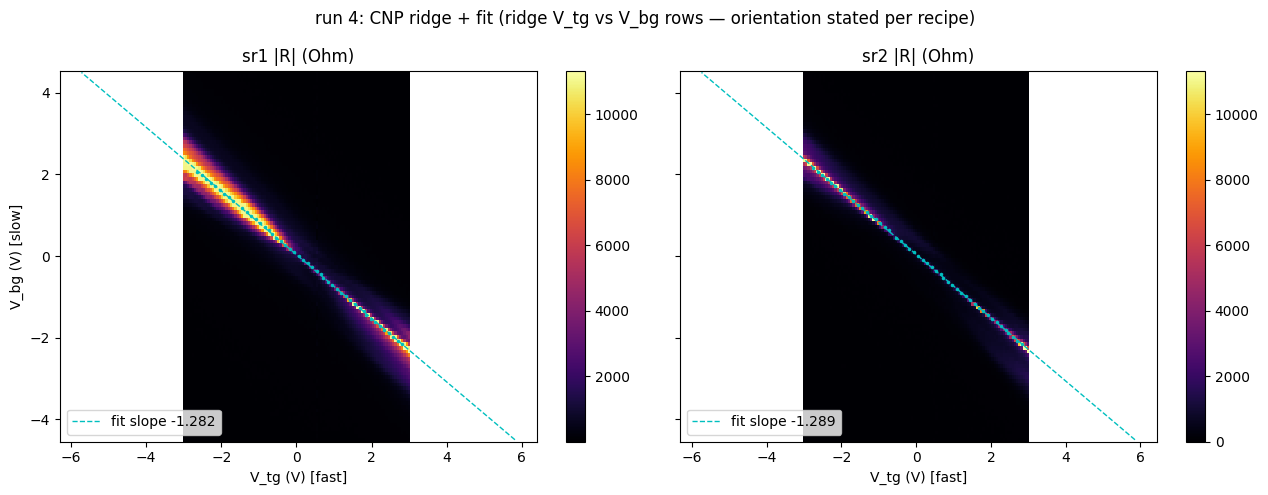


combined slope -1.2852 (c_bg/c_tg = 1.2852; geometry prior 1.300, -1.1%)
c_tg = 1.7027e-03 F/m^2 (prior anchor), c_bg = 2.1884e-03 F/m^2 (ratio-calibrated)
n_offset = -0.0546 e12 cm^-2; D_offset = 0 (stated assumption — no D-symmetric feature examined yet)
D=0 realized n window: [-6.43, 6.32] e12 cm^-2 (TG-limited)
  n = -6.0 e12 cm^-2, D=0 -> (Vtg, Vbg) = (-2.797, -2.176); F_L = 62.0 T, Nyquist d(1/B) <= 8.06e-03 /T
  n = +6.0 e12 cm^-2, D=0 -> (Vtg, Vbg) = (+2.849, +2.216); F_L = 62.0 T, Nyquist d(1/B) <= 8.06e-03 /T


In [2]:
# run 4: CNP ridge extraction + (n,D) calibration (cnp-and-dline-calibration steps 0-4)
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from hera.analysis import fan_grids, resistance_grids, GateCalibration, luttinger_frequency
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

fg = fan_grids("data/4")
rg = resistance_grids(fg, channels=["sr1", "sr2"])
Vbg, Vtg = fg.slow, fg.grid("k_2400_tg_volt")[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
fits = {}
for ax, ch in zip(axes, ("sr1", "sr2")):
    R = np.abs(rg.R[ch])
    Rs = gaussian_filter1d(R, sigma=2, axis=1)
    idx = Rs.argmax(axis=1)
    ridge, peakR = Vtg[idx], Rs[np.arange(len(idx)), idx]
    edge = (idx <= 2) | (idx >= len(Vtg) - 3)          # guard: edge-clipped rows
    keep = ~edge
    for _ in range(5):                                  # guard: robust fit
        p = np.polyfit(Vbg[keep], ridge[keep], 1)
        res = ridge - np.polyval(p, Vbg)
        new = ~edge & (np.abs(res) < 2 * res[keep].std())
        if (new == keep).all():
            break
        keep = new
    rms = (ridge[keep] - np.polyval(p, Vbg[keep])).std()
    fits[ch] = p
    print(f"{ch}: slope {p[0]:+.4f}, intercept {p[1]:+.4f} V, rms {rms*1e3:.1f} mV, "
          f"rows kept {keep.sum()}/101 (edge-clipped {edge.sum()}), "
          f"ridge peak R [{peakR[keep].min():.0f}, {peakR[keep].max():.0f}] Ohm")
    pc = ax.pcolormesh(Vtg, Vbg, R, shading="auto", cmap="inferno")
    ax.plot(ridge[keep], Vbg[keep], "c.", ms=3)
    ax.plot(np.polyval(p, Vbg), Vbg, "c--", lw=1, label=f"fit slope {p[0]:+.3f}")
    ax.set_xlabel("V_tg (V) [fast]"); ax.set_title(f"{ch} |R| (Ohm)"); ax.legend(loc="lower left")
    fig.colorbar(pc, ax=ax)
axes[0].set_ylabel("V_bg (V) [slow]")
fig.suptitle("run 4: CNP ridge + fit (ridge V_tg vs V_bg rows — orientation stated per recipe)")
fig.tight_layout(); plt.show()

# conversion: ratio data-calibrated, scale anchored on c_tg stack prior (15.6 nm hBN)
slope = np.mean([fits[c][0] for c in fits]); b = np.mean([fits[c][1] for c in fits])
c_tg = stack_capacitance([(15.6, 3)])
c_bg = -slope * c_tg
n_off_disp = -calc_nD(b, 0, c_tg, c_bg)[0]           # sharpelab display units: 1e12 cm^-2
cal = GateCalibration(c_tg=c_tg, c_bg=c_bg, n_offset=n_off_disp * 1e16, D_offset=0.0)  # SI
print(f"\ncombined slope {slope:+.4f} (c_bg/c_tg = {-slope:.4f}; geometry prior 1.300, {100*(-slope/1.3-1):+.1f}%)")
print(f"c_tg = {c_tg:.4e} F/m^2 (prior anchor), c_bg = {c_bg:.4e} F/m^2 (ratio-calibrated)")
print(f"n_offset = {n_off_disp:+.4f} e12 cm^-2; D_offset = 0 (stated assumption — no D-symmetric feature examined yet)")

# D=0 line, clipped to validators by dropping; realized window + F_L
ns = np.linspace(-8, 8, 1601)
vt, vb = calc_gate_voltages(ns, np.zeros_like(ns), c_tg, c_bg, n_offset=n_off_disp)
ok = (vt >= -3.0) & (vt <= 3.0) & (vb >= -4.5) & (vb <= 4.5)
print(f"D=0 realized n window: [{ns[ok].min():.2f}, {ns[ok].max():.2f}] e12 cm^-2 (TG-limited)")
for n_req in (-6.0, 6.0):
    vtg_p, vbg_p = calc_gate_voltages(n_req, 0.0, c_tg, c_bg, n_offset=n_off_disp)
    FL = float(luttinger_frequency(abs(n_req) * 1e16))
    print(f"  n = {n_req:+.1f} e12 cm^-2, D=0 -> (Vtg, Vbg) = ({vtg_p:+.3f}, {vbg_p:+.3f}); "
          f"F_L = {FL:.1f} T, Nyquist d(1/B) <= {1/(2*FL):.2e} /T")


## Step 1 take — calibration contract (run 4)

- **Ratio (data-calibrated):** c_bg/c_tg = **1.2852** — sr1 −1.2817 / sr2 −1.2887, 0.5% apart → one calibration for the device (cross-channel check passed; disagreement < per-channel scatter). Geometry sanity: prior ratio 15.6/12 = 1.300, fitted −1.1% — agreement, Verify passed.
- **Scale (geometry prior):** c_tg anchored at the 15.6 nm hBN stack prior (1.703e-3 F/m²), c_bg = 2.188e-3 F/m² from the ratio. **Absolute n/D carry the geometry-prior uncertainty until the SdH/QH lever-arm upgrade** (two-tier provenance, recipe step 5).
- **Offsets:** n_offset = −0.055×10¹² cm⁻² (intercept +0.051 V); D_offset = 0 — stated assumption, no D-symmetric feature examined yet. Fit quality: rms 20 mV ≈ 0.02×10¹² cm⁻² in n.
- **CNP-vs-D magnitude read (domain-aware, not a stacking call):** ridge peak R rises ~10× moving away from the D=0 crossing on both sides — sr2 from ~0.5 kΩ to ~7 kΩ; sr1 from ~1.3 kΩ into its 10.9 kΩ sensitivity soft-clip ceiling (railed rows; position still fit-usable, magnitude truncated). A D-opened gap at CNP is **consistent-with ABC (or mixed ABA/ABC)** — per the investigation this feeds the per-channel read only; the FS count decides. The cap at ~10 kΩ (≪ MΩ) is itself consistent-with domain shunting — not evidence against ABC.
- **D = 0 line:** realized |n| ≤ ~6.3×10¹² cm⁻² (TG-limited). Operating points for Step 3: n = ±6×10¹² cm⁻² at D = 0 → (V_tg, V_bg) = (+2.849, +2.216) / (−2.797, −2.176). **F_L = 62.0 T** at |n| = 6×10¹² cm⁻²; Nyquist Δ(1/B) ≤ 8.06e-3 /T.

**Next:** Step 3 — SdH spot checks at n = ±6×10¹² cm⁻², D = 0 (`sdh-spot-check`, uniform-B sampling for this blocking magnet), electron side first.


# Step 3a — electron SdH spot check (run 5): read + acquisition verdict

Run 5: n = +6×10¹² cm⁻², D = 0, B 0.5→8 T uniform-B (measure cell c714a33d), 1547/1547 rows, 2.3 h. **Acquisition fault found and owned**: sr1/sr2 sensitivities were sized from the B = 0 resistance (~30 Ω) without budgeting the positive MR — R(B) grew ~5× by 2.5 T, soft-clipping sr1 at 109 Ω (from 2.51 T) and sr2 at 54.6 Ω (from 2.33 T). Usable record truncated to ≲2.4 T (`sdh_onset` `r_full_scale` handling). Raw first, FFT read on the surviving window, then the redo plan.


C:\Users\DGG\AppData\Local\Temp\ipykernel_5228\2796370304.py:20: UserWarning: sdh_onset: |R| reaches 109 Ω vs full scale 100 Ω (soft clip, ≥0.95x from B = 2.51 T); analysis window truncated to 2.51 T
  on = sdh_onset(R, B, r_full_scale=rfs)
C:\Users\DGG\AppData\Local\Temp\ipykernel_5228\2796370304.py:20: UserWarning: sdh_onset: untracked tone(s): 11.2 T (never above threshold (max SNR 4.3 vs 5 across 8 windows)); 14.1 T (never above threshold (max SNR 3.8 vs 5 across 10 windows)); 8.3 T (never above threshold (max SNR 3.9 vs 5 across 5 windows)); 4.2 T (never above threshold (max SNR 3.2 vs 5 across 1 windows)); 22.0 T (never above threshold (max SNR 3.6 vs 5 across 18 windows))
  on = sdh_onset(R, B, r_full_scale=rfs)
C:\Users\DGG\AppData\Local\Temp\ipykernel_5228\2796370304.py:20: UserWarning: sdh_onset: |R| reaches 54.6 Ω vs full scale 50 Ω (soft clip, ≥0.95x from B = 2.33 T); analysis window truncated to 2.33 T
  on = sdh_onset(R, B, r_full_scale=rfs)
C:\Users\DGG\AppData\Local\Tem

=== sr1 ===
sdh_onset: onset_b = 1.66 T (tone 64.9 T) over B [0.51, 2.51] T
  tone   64.9 T: onset  1.66 T  dF  4.87 T  snr_max   10.1  [~2x32.7T]
  tone   32.7 T: onset  1.93 T  dF  8.35 T  snr_max    5.6  [marginal, ~3x11.2T, 2x->64.9T]
  tone   43.6 T: onset  2.08 T  dF 12.02 T  snr_max    6.2  [marginal, ~4x11.2T]
  tone   11.2 T: UNTRACKED — never above threshold (max SNR 4.3 vs 5 across 8 windows)
  tone   14.1 T: UNTRACKED — never above threshold (max SNR 3.8 vs 5 across 10 windows)
  tone    8.3 T: UNTRACKED — never above threshold (max SNR 3.9 vs 5 across 5 windows)
  tone    4.2 T: UNTRACKED — never above threshold (max SNR 3.2 vs 5 across 1 windows)
  tone   22.0 T: UNTRACKED — never above threshold (max SNR 3.6 vs 5 across 18 windows)
=== sr2 ===
sdh_onset: onset_b = 1.21 T (tone 53.9 T) over B [0.51, 2.33] T
  tone   53.9 T: onset  1.21 T  dF  2.53 T  snr_max   23.2  [revives-below-gap, ~5x11.3T]
  tone   11.3 T: onset  1.18 T  dF  2.40 T  snr_max    8.8  [marginal, 2x->22

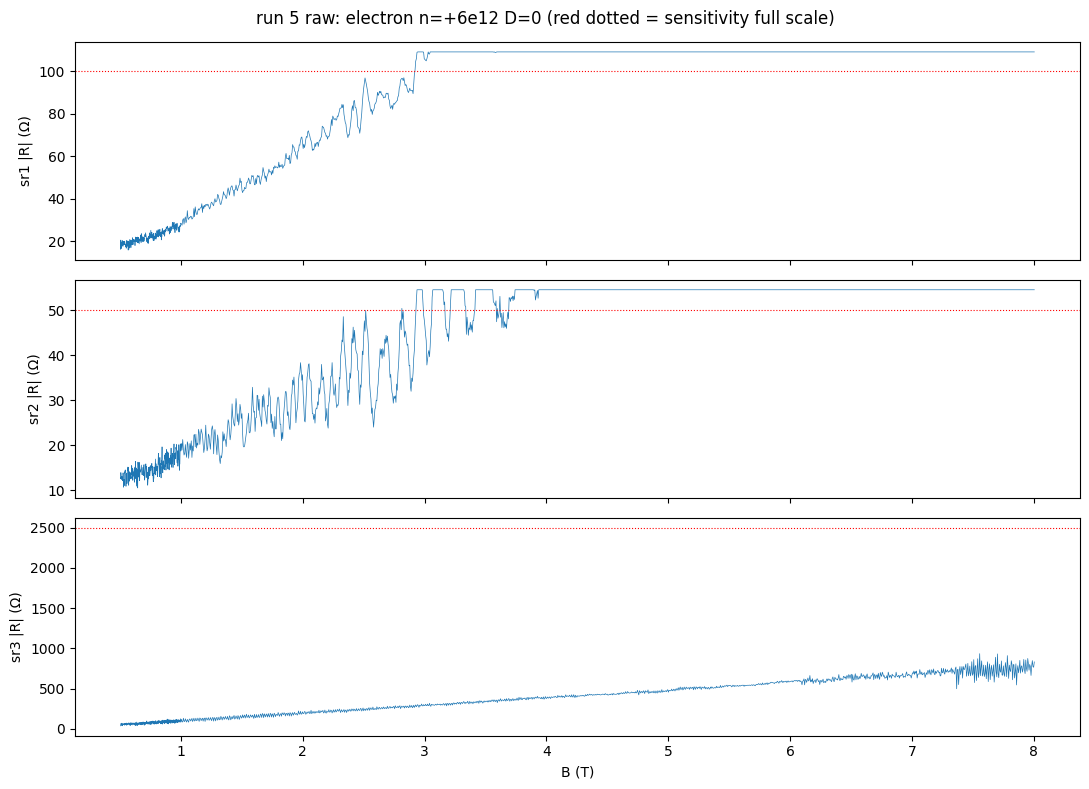

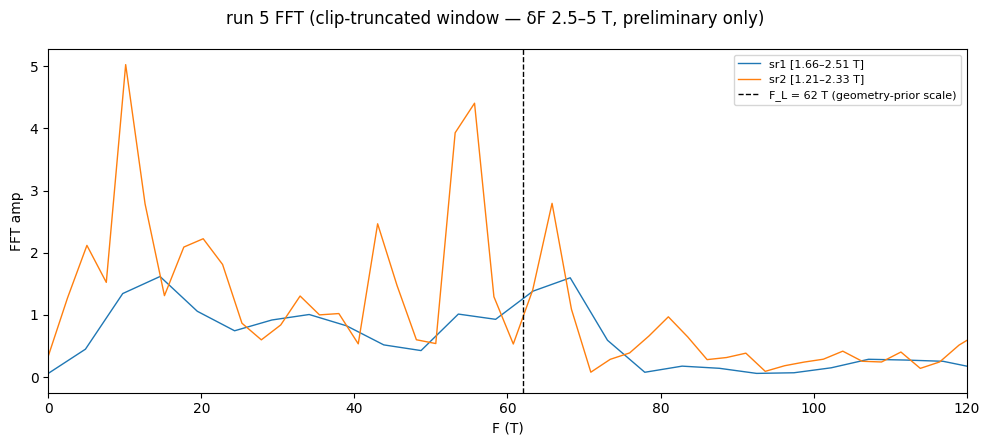


Hall slope (0.5–1.5 T): 94.6 Ω/T -> n_Hall = 6.60 e12 cm^-2 (target +6.0; geometry-prior scale check)


In [3]:
# run 5: raw traces, onset, FFT on the unclipped window
import numpy as np
import matplotlib.pyplot as plt
from hera.analysis import open_run, sdh_onset, sdh_fft, SdhOnsetError

run = open_run("data/5")
B = run.col_at(4)               # measured field (col 1 is the setpoint instance)
I_BIAS = 20e-9
SENS = {"sr1": 2e-6, "sr2": 1e-6, "sr3": 5e-5}

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
onsets = {}
for ax, ch in zip(axes, ("sr1", "sr2", "sr3")):
    R = np.abs(run.col(f"{ch}_X")) / I_BIAS
    ax.plot(B, R, lw=0.5)
    rfs = SENS[ch] / I_BIAS
    ax.axhline(rfs, color="r", ls=":", lw=0.8)
    ax.set_ylabel(f"{ch} |R| (Ω)")
    try:
        on = sdh_onset(R, B, r_full_scale=rfs)
        onsets[ch] = on
        print(f"=== {ch} ===")
        print(on.summary())
    except SdhOnsetError as e:
        print(f"=== {ch} === no usable oscillations: {e}")
axes[-1].set_xlabel("B (T)")
fig.suptitle("run 5 raw: electron n=+6e12 D=0 (red dotted = sensitivity full scale)")
fig.tight_layout(); plt.show()

fig2, ax2 = plt.subplots(figsize=(10, 4.5))
for ch in ("sr1", "sr2"):
    on = onsets[ch]
    R = np.abs(run.col(f"{ch}_X")) / I_BIAS
    b_hi = on.clip_high_b if on.clip_high_b else B.max()
    freqs, spec = sdh_fft(R[:, None], B, b_range=(max(on.onset_b, 0.9), b_hi))
    ax2.plot(freqs, spec[0], lw=1, label=f"{ch} [{max(on.onset_b,0.9):.2f}–{b_hi:.2f} T]")
ax2.axvline(62.0, color="k", ls="--", lw=1, label="F_L = 62 T (geometry-prior scale)")
ax2.set_xlim(0, 120); ax2.set_xlabel("F (T)"); ax2.set_ylabel("FFT amp"); ax2.legend(fontsize=8)
fig2.suptitle("run 5 FFT (clip-truncated window — δF 2.5–5 T, preliminary only)")
fig2.tight_layout(); plt.show()

# free lever-arm cross-check from the Hall channel (low field, before QH structure)
m = (B > 0.5) & (B < 1.5)
Rxy = np.abs(run.col("sr3_X")) / I_BIAS
p = np.polyfit(B[m], Rxy[m], 1)
n_hall = 1 / (1.602e-19 * p[0]) * 1e-16
print(f"\nHall slope (0.5–1.5 T): {p[0]:.1f} Ω/T -> n_Hall = {n_hall:.2f} e12 cm^-2 (target +6.0; geometry-prior scale check)")


## Run 5 take — preliminary tones, and the redo decision

**Usable window** 0.5–2.4 T (clip-truncated); onset ≈ 1.2 T (sr2 tone-tracked; sr1 1.7 T) — well resolved above the 0.5 T floor, so the onset is *measured*, not censored. **Hall cross-check**: slope 94.6 Ω/T (0.5–1.5 T) → n_Hall ≈ 6.6×10¹² cm⁻² vs target 6.0 — suggests the geometry-prior scale reads ~10% low (caveat: low-B Hall in a possible two-band system is an indicator, not a calibration). **F_L is therefore a band, ≈ 62–68 T**; the scale gets pinned properly by the Luttinger sum over the full peak set (investigation: pin the scale before you reject).

**Preliminary peak sets (δF 2.5–5 T on this short record — read loosely):**
- **sr2 (B4–B5)**: strong 53.9 T + marginal 11.3 T, with 22.2 ≈ 2×11.3 and 72.4 ≈ 6×11.3 flagged as harmonic-comb members. Two competing readings: (a) **ABA pair** {f_ML ≈ 11.3, f_BL ≈ 53.9}, sum 65.2 — inside the F_L band ✓; (b) an 11.3 T harmonic comb with 53.9 accidentally ≈ 5×11.3 (56.5 — off by 2.6 ≈ δF, unresolvable here).
- **sr1 (T3–T4)**: single dominant ≈ 64.9 T, inside the F_L band (weak 32.7 ≈ f/2 flag), *no clear small partner* — on this record consistent-with an ABC singleton in that region → **mixed-domain candidate** (channels disagree = signal, per the investigation). But: a tone absent from a clipped record is unresolved, not absent.
- sr3 (Hall): clean linear + developing QH structure ≥6 T; not an SdH-FFT channel here.

**Acquisition verdict: redo before any claim strength** (investigation Verify: fix acquisition; a clean spot check must carry the call). The 2.4–8 T record — where the oscillations are deepest and δF would drop to ~1.4 T — is what the clip cost.

**Redo plan (measure cells following):**
1. **Run 6** — electron re-acquire, **8 → 2.0 T down-sweep** (magnet sits at 8 T; never re-traverse), 5.4 mT, sens sr1 1e-5 / sr2 5e-6 (≈1.4× above the linear-MR extrapolation to 8 T: ~360/180 Ω; the riskiest, highest-R rows come **first** in a down-sweep — first-rows checkpoint kills a wrong guess in minutes). 0.5 T overlap with run 5's usable window for the stitch/grid-change check. ~1.7 h.
2. **Run 7** — hole onset segment: gates to (−2.797, −2.176) at 2 T, **2.0 → 0.5 T** at 2.0 mT, mid sens (sr1 5e-6 / sr2 2e-6). ~51 min.
3. **Run 8** — hole main record: **0.5 → 8 T** (bare ramp to 1.0, points 1.0 → 8.0 at 5.4 mT), coarse sens as run 6. ~2.0 h. Ends at 8 T, fan-ready.

The held hole cell 0b8ef9ac is **superseded** (wrong sens, wrong traverse) — left unexecuted per append-only discipline.


# Step 3 electron read — runs 5+6: peak sets, pinned scale, template match

Run 6 (electron redo, 8→2 T, unclipped; 1112/1112 rows) + run 5's clean 0.5–2.4 T fine segment. Analysis: `sdh_onset`/`sdh_fft` per channel, FFT stability sweep (bg_degree 3/5/7 × three windows — principal tones stationary), harmonic screen, Luttinger scale pin, forward-model comparison (`hera/models/trilayer_fs_count/fs_count_b0.py`), and the F_L-tone-origin B-window split.


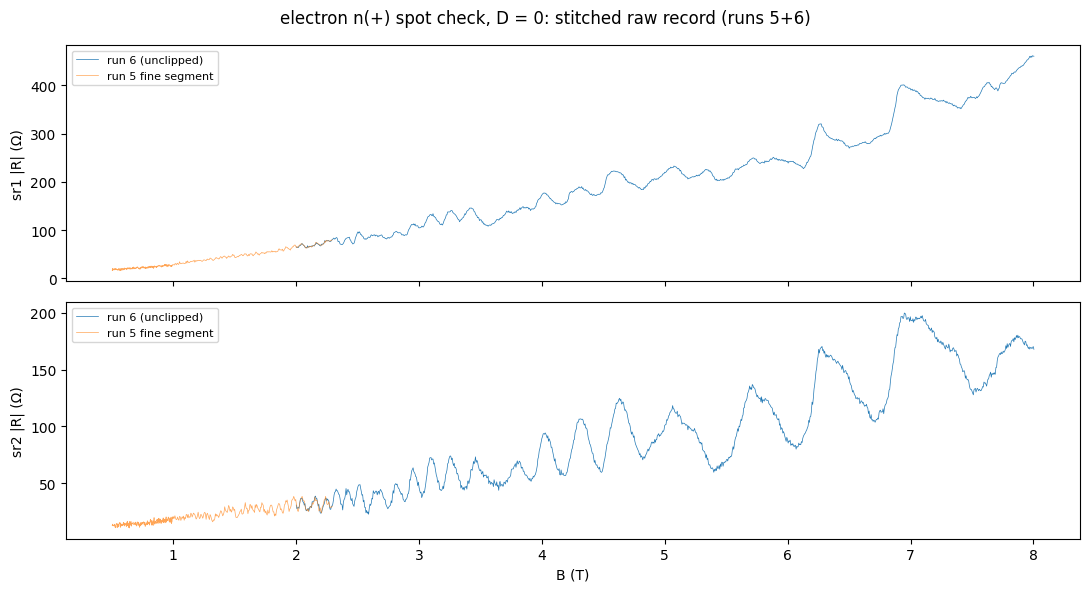

C:\Users\DGG\AppData\Local\Temp\ipykernel_5228\1591928519.py:28: UserWarning: sdh_onset: tone 66.3 T is above threshold through the lowest window — oscillations persist to the record's low edge; onset_b = 2.00 T is the record edge, not a measured die-off
  on = sdh_onset(R, B6s, r_full_scale=sens / I_BIAS)
C:\Users\DGG\AppData\Local\Temp\ipykernel_5228\1591928519.py:28: UserWarning: sdh_onset: tone 55.2 T is above threshold through the lowest window — oscillations persist to the record's low edge; onset_b = 2.00 T is the record edge, not a measured die-off
  on = sdh_onset(R, B6s, r_full_scale=sens / I_BIAS)


=== sr1 ===
sdh_onset: onset_b = 2.00 T (tone 66.3 T) over B [2.00, 8.00] T
  tone   66.3 T: onset  2.00 T  dF  2.67 T  snr_max   98.5  [censored@edge, ~5x13.4T, 2x->132.0T, 4x->261.6T]
  tone   98.9 T: onset  3.27 T  dF  5.52 T  snr_max   64.0  [revives-below-gap]
  tone   13.4 T: onset  2.00 T  dF  2.67 T  snr_max   70.9  [censored@edge, near-residual, 2x->27.9T, 3x->38.8T, 5x->66.3T, 14x->181.9T]
  tone   38.8 T: onset  2.66 T  dF  3.98 T  snr_max   86.7  [~3x13.4T]
  tone  181.9 T: onset  4.23 T  dF  8.95 T  snr_max   65.9  [~14x13.4T]
  tone   27.9 T: onset  2.00 T  dF  2.67 T  snr_max   53.0  [censored@edge, ~2x13.4T]
  tone  261.6 T: onset  5.29 T  dF 15.64 T  snr_max   47.1  [revives-below-gap, ~4x66.3T]
  tone  132.0 T: onset  3.14 T  dF  5.17 T  snr_max  105.9  [~2x66.3T]

=== sr2 ===
sdh_onset: onset_b = 2.00 T (tone 55.2 T) over B [2.00, 8.00] T
  tone   55.2 T: onset  2.00 T  dF  2.67 T  snr_max  143.9  [censored@edge, ~4x13.4T]
  tone  120.6 T: onset  3.47 T  dF  6.13 T  

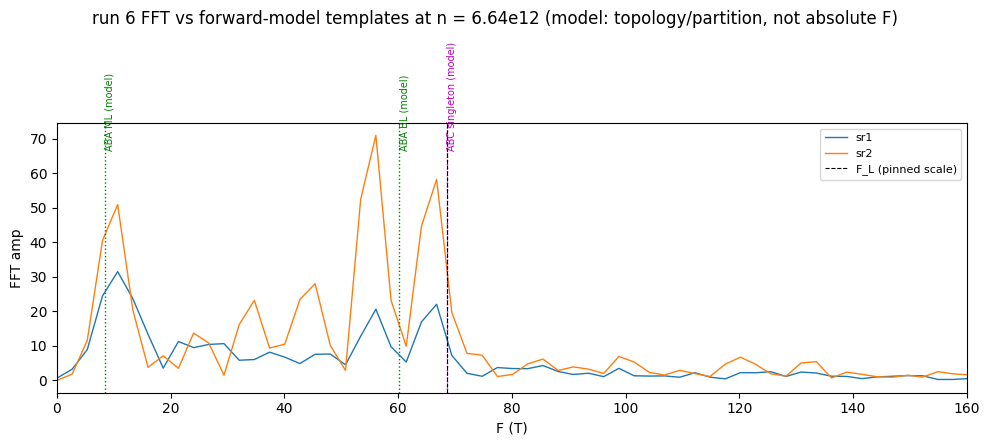

=== B-window split (amp ratios low->high B) ===
sr1: 66/13 1.27 -> 1.07; 66/55 1.09 -> 0.88
sr2: 66/13 2.93 -> 1.38; 66/55 0.90 -> 0.66
falling ratios both channels -> F_L tone does NOT grow with B: consistent with a real pocket, not breakdown


In [4]:
# electron full read: stitched record, per-channel FFT, scale pin, model overlay, B-split
import sys
import numpy as np
import matplotlib.pyplot as plt
from hera.analysis import open_run, sdh_onset, sdh_fft
sys.path.insert(0, r"C:/Users/DGG/measurement_env/hera/models/trilayer_fs_count")
from fs_count_b0 import aba_fs, abc_fs, aba_mstar

I_BIAS = 20e-9
r5, r6 = open_run("data/5"), open_run("data/6")
B5, B6 = r5.col_at(4), r6.col_at(4)
o6 = np.argsort(B6)
B6s = B6[o6]

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, ch in zip(axes, ("sr1", "sr2")):
    ax.plot(B6s, np.abs(r6.col(f"{ch}_X"))[o6] / I_BIAS, lw=0.5, label="run 6 (unclipped)")
    m5 = B5 < 2.3
    ax.plot(B5[m5], np.abs(r5.col(f"{ch}_X"))[m5] / I_BIAS, lw=0.5, alpha=0.7, label="run 5 fine segment")
    ax.set_ylabel(f"{ch} |R| (Ω)"); ax.legend(fontsize=8)
axes[-1].set_xlabel("B (T)")
fig.suptitle("electron n(+) spot check, D = 0: stitched raw record (runs 5+6)")
fig.tight_layout(); plt.show()

# tone tables (run 6)
for ch, sens in (("sr1", 1e-5), ("sr2", 5e-6)):
    R = np.abs(r6.col(f"{ch}_X"))[o6] / I_BIAS
    on = sdh_onset(R, B6s, r_full_scale=sens / I_BIAS)
    print(f"=== {ch} ===\n{on.summary()}\n")

# FFT overlay vs templates at the pinned scale
fig2, ax2 = plt.subplots(figsize=(10, 4.5))
for ch in ("sr1", "sr2"):
    R = np.abs(r6.col(f"{ch}_X"))[o6] / I_BIAS
    f, s = sdh_fft(R[:, None], B6s, b_range=(2.0, 8.0), nfft=4096)
    ax2.plot(f, s[0], lw=1, label=ch)
n_pin = 6.64e16   # from Luttinger sum (68.6 T) — agrees with Hall (6.60e12) to 0.5%
_, orb = aba_fs(n_pin)
for (F, _), lab in zip(orb, ("ABA ML (model)", "ABA BL (model)")):
    ax2.axvline(F, color="g", ls=":", lw=1); ax2.text(F, ax2.get_ylim()[1]*0.9, lab, rotation=90, fontsize=7, color="g")
_, _, _, _, Ftot = abc_fs(n_pin)
ax2.axvline(Ftot, color="m", ls=":", lw=1); ax2.text(Ftot, ax2.get_ylim()[1]*0.9, "ABC singleton (model)", rotation=90, fontsize=7, color="m")
ax2.axvline(68.6, color="k", ls="--", lw=0.8, label="F_L (pinned scale)")
ax2.set_xlim(0, 160); ax2.set_xlabel("F (T)"); ax2.set_ylabel("FFT amp"); ax2.legend(fontsize=8)
fig2.suptitle("run 6 FFT vs forward-model templates at n = 6.64e12 (model: topology/partition, not absolute F)")
fig2.tight_layout(); plt.show()

# F_L-tone origin: B-window split (breakdown strengthens with B; a pocket keeps its envelope)
print("=== B-window split (amp ratios low->high B) ===")
for ch in ("sr1", "sr2"):
    R = np.abs(r6.col(f"{ch}_X"))[o6] / I_BIAS
    out = {}
    for lab, br in (("low", (2.0, 3.2)), ("high", (3.2, 8.0))):
        f, s = sdh_fft(R[:, None], B6s, b_range=br, nfft=4096)
        amp = lambda F0: s[0][(f > F0 - 4) & (f < F0 + 4)].max()
        out[lab] = (amp(13.4), amp(55.2), amp(66.3))
    lo, hi = out["low"], out["high"]
    print(f"{ch}: 66/13 {lo[2]/lo[0]:.2f} -> {hi[2]/hi[0]:.2f}; 66/55 {lo[2]/lo[1]:.2f} -> {hi[2]/hi[1]:.2f}")
print("falling ratios both channels -> F_L tone does NOT grow with B: consistent with a real pocket, not breakdown")


## Electron-side take (preliminary — fan + LK mass pending)

**Scale pinned by two independent reads agreeing to 0.5%** (investigation: pin the scale before you reject): sr2's Luttinger partition 13.4 + 55.2 = 68.6 T → n = 6.64×10¹² cm⁻²; low-B Hall → 6.60×10¹². Global scale = 1.106× geometry prior. All tones below are read against **F_L = 68.6 T**.

**Peak sets (run 6, 2–8 T, δF ≈ 2.7 T; stability-sweep-stationary):**
- **sr2 (B4–B5): {13.4, 55.2}** — partition sums to F_L exactly; template-matches the ABA pair (model at pinned n: ML 8.4, BL 60.2 — same topology, absolute F within the model's stated hopping-parameter bars). Harmonic screen: 55.2 sits near 4×13.4 (53.6) but is 4× *stronger* than 13.4 — a harmonic never outruns its fundamental; both stand as fundamentals. 24.8 ≈ 2×13.4 dropped as harmonic; 33.9 unassigned (fork to carry).
- **sr1 (T3–T4): {13.4, 66.3}** — 66.3 sits **at F_L** (ABC-singleton model: 68.7), the 55.2 tone is absent, and 13.4 rides with its 2×/3× comb. 98.9 ≈ 1.5×66.3 unassigned (spin-split or combination — fork to carry).
- **F_L-tone origin (Verify)**: B-window split — 66.3's amplitude relative to both fundamentals *falls* toward high B (1.27→1.07, 1.09→0.88); breakdown would strengthen ~exp(−B₀/B). **Consistent with a real ABC-domain pocket, not breakdown.** Grid-change reproduction pending (run 5 vs 6 overlap); LK mass split is the decisive check (in-arc).

**Emerging region-resolved picture (electron side): mixed-stacking mosaic** — the segment sr2 probes shows the ABA pair; the segment sr1 probes shows an ABC-like singleton plus the shared/leaked 13.4. Channels kept separate throughout per the investigation; this is the expected signature of ABA/ABC domains between different contact pairs.

**Hedges**: single density so far; 33.9 (sr2) and 98.9 (sr1) unassigned; ABA-vs-comb ambiguity for 13.4's family resolved only by the fan's n-tracking (a harmonic tracks k·f exactly; a pocket follows its own Onsager curve); absolute F model bars are wide — topology/partition matched, not positions.

**Next**: hole-side records (runs 7–8, acquiring), then the D = 0 fan on the cleaner side inheriting this acquisition; LK mass split at the fan's operating point.


# Step 3 hole read — runs 7+8, and the fan side choice

Run 7 (2→0.5 T fine, onset segment) + run 8 (1→8 T main, 1297/1297; sr1 soft-clipped only above ~7.5 T — up-sweep put the risky rows last, caught at completion; truncation costs Δ(1/B) ≈ 0.01, no redo). Onset ≈ 1.16 T (measured). Hole Hall: 98.3 Ω/T → n_Hall = 6.35×10¹² (scale 1.06× vs electron 1.106× — slight e/h asymmetry, carried as a hedge).

**Peak sets:** sr1 {11.0, 54.4} (+16.2, 26.6, 71.7); sr2 {11.4, 54.5} (+5.8 near-residual, 16.0, 72.1). **Both channels pair-dominated; partition 65.4–65.9 ≈ F_L(hole scale) = 65.6 ✓** — a second independent Luttinger-consistent ABA partition, on the opposite carrier sign. Model hole ABA {12.2, 56.5}: topology and rough positions match. No standalone F_L singleton on this side (72-ish tone present on both sides, unassigned — fork). The 16 T tone (both channels) is a new unassigned member — fork for the fan.

**Fan side choice: electron** — matched SNR both sides, but the electron side carries the region contrast (sr1 singleton-at-F_L vs sr2 pair) that the region-resolved call needs. Fan cell efa48495 executes next, riding the magnet down from 8 T.


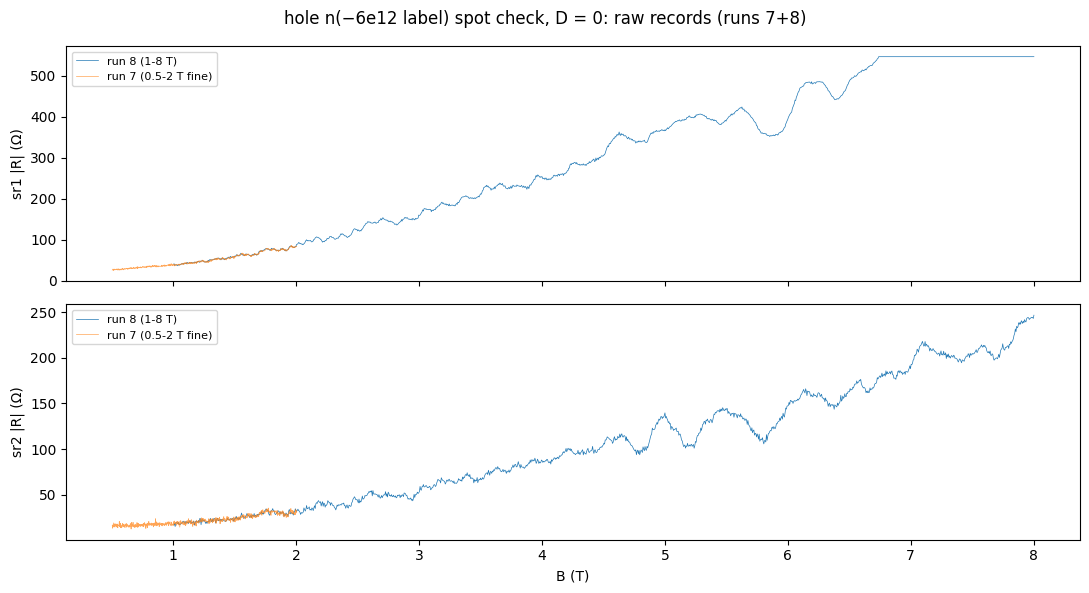

=== sr1 (run 8) ===
sdh_onset: onset_b = 1.01 T (tone 11.0 T) over B [1.01, 6.13] T
  tone   11.0 T: onset  1.01 T  dF  1.20 T  snr_max   39.2  [censored@edge, 2x->24.3T, 5x->54.4T, 7x->71.7T, 23x->254.6T]
  tone   54.4 T: onset  1.63 T  dF  2.22 T  snr_max   79.4  [~5x11.0T]
  tone   93.1 T: onset  2.77 T  dF  5.05 T  snr_max   25.9  [~6x16.2T]
  tone   16.2 T: onset  1.66 T  dF  2.28 T  snr_max   24.0  [6x->93.1T]
  tone   71.7 T: onset  2.40 T  dF  3.94 T  snr_max   46.9  [revives-below-gap, ~7x11.0T]
  tone   26.6 T: onset  1.94 T  dF  2.83 T  snr_max   14.3
  tone   24.3 T: onset  2.12 T  dF  3.25 T  snr_max   19.1  [~2x11.0T]
  tone  254.6 T: onset  4.57 T  dF 17.92 T  snr_max   11.6  [~23x11.0T]

=== sr2 (run 8) ===
sdh_onset: onset_b = 1.01 T (tone 11.4 T) over B [1.01, 7.88] T
  tone   54.5 T: onset  1.80 T  dF  2.33 T  snr_max  122.0  [~5x11.4T]
  tone   11.4 T: onset  1.01 T  dF  1.15 T  snr_max   26.1  [censored@edge, ~2x5.8T, 5x->54.5T, 12x->135.2T]
  tone   72.1 T: onset 

C:\Users\DGG\AppData\Local\Temp\ipykernel_5228\1759455955.py:22: UserWarning: sdh_onset: |R| reaches 546 Ω vs full scale 500 Ω (soft clip, ≥0.95x from B = 6.13 T); analysis window truncated to 6.13 T
  on = sdh_onset(R, B8[o8], r_full_scale=sens / I_BIAS)
C:\Users\DGG\AppData\Local\Temp\ipykernel_5228\1759455955.py:22: UserWarning: sdh_onset: tone 11.0 T is above threshold through the lowest window — oscillations persist to the record's low edge; onset_b = 1.01 T is the record edge, not a measured die-off
  on = sdh_onset(R, B8[o8], r_full_scale=sens / I_BIAS)
C:\Users\DGG\AppData\Local\Temp\ipykernel_5228\1759455955.py:22: UserWarning: sdh_onset: |R| reaches 247 Ω vs full scale 250 Ω (soft clip, ≥0.95x from B = 7.88 T); analysis window truncated to 7.88 T
  on = sdh_onset(R, B8[o8], r_full_scale=sens / I_BIAS)
C:\Users\DGG\AppData\Local\Temp\ipykernel_5228\1759455955.py:22: UserWarning: sdh_onset: tone 11.4 T is above threshold through the lowest window — oscillations persist to the r

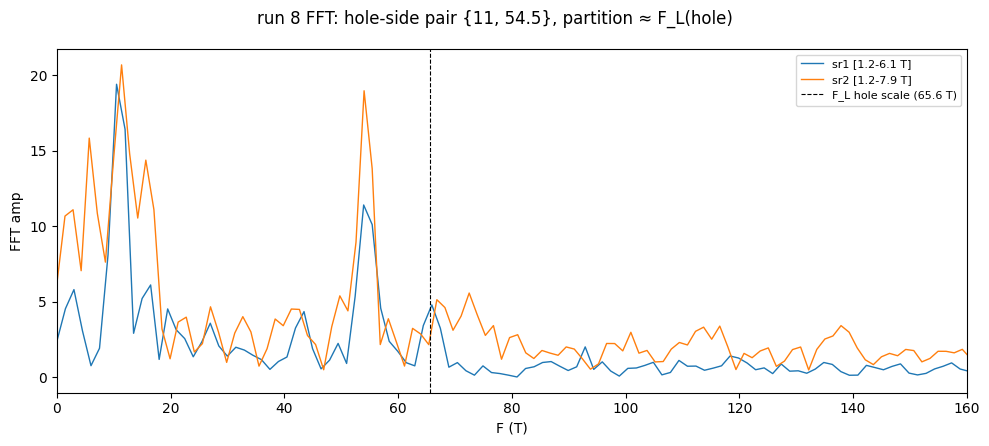

In [5]:
# hole side: stitched raw + tone tables + FFT vs hole-scale F_L
import numpy as np
import matplotlib.pyplot as plt
from hera.analysis import open_run, sdh_onset, sdh_fft

I_BIAS = 20e-9
r7, r8 = open_run("data/7"), open_run("data/8")
B7, B8 = r7.col_at(4), r8.col_at(4)
o7, o8 = np.argsort(B7), np.argsort(B8)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, ch in zip(axes, ("sr1", "sr2")):
    ax.plot(B8[o8], np.abs(r8.col(f"{ch}_X"))[o8] / I_BIAS, lw=0.5, label="run 8 (1-8 T)")
    ax.plot(B7[o7], np.abs(r7.col(f"{ch}_X"))[o7] / I_BIAS, lw=0.5, alpha=0.7, label="run 7 (0.5-2 T fine)")
    ax.set_ylabel(f"{ch} |R| (Ω)"); ax.legend(fontsize=8)
axes[-1].set_xlabel("B (T)")
fig.suptitle("hole n(−6e12 label) spot check, D = 0: raw records (runs 7+8)")
fig.tight_layout(); plt.show()

for ch, sens in (("sr1", 1e-5), ("sr2", 5e-6)):
    R = np.abs(r8.col(f"{ch}_X"))[o8] / I_BIAS
    on = sdh_onset(R, B8[o8], r_full_scale=sens / I_BIAS)
    print(f"=== {ch} (run 8) ===\n{on.summary()}\n")

fig2, ax2 = plt.subplots(figsize=(10, 4.5))
for ch, sens in (("sr1", 1e-5), ("sr2", 5e-6)):
    R = np.abs(r8.col(f"{ch}_X"))[o8] / I_BIAS
    on = sdh_onset(R, B8[o8], r_full_scale=sens / I_BIAS)
    b_hi = on.clip_high_b if on.clip_high_b else B8[o8].max()
    f, s = sdh_fft(R[:, None], B8[o8], b_range=(1.2, b_hi), nfft=4096)
    ax2.plot(f, s[0], lw=1, label=f"{ch} [1.2-{b_hi:.1f} T]")
ax2.axvline(65.6, color="k", ls="--", lw=0.8, label="F_L hole scale (65.6 T)")
ax2.set_xlim(0, 160); ax2.set_xlabel("F (T)"); ax2.set_ylabel("FFT amp"); ax2.legend(fontsize=8)
fig2.suptitle("run 8 FFT: hole-side pair {11, 54.5}, partition ≈ F_L(hole)")
fig2.tight_layout(); plt.show()


# Step 4/5 — Landau fan (run 9): per-column FFT, tone tracks, partition across density

Run 9: D = 0 electron side, B 8→1.2 T × 131 (1/B-uniform, Δ(1/B) = 5.4e-3 spot-check-inherited), n 2.0→6.2×10¹² labels × 81, 6τ dwell, 10611/10611 rows, 7.1 h, T_sample 1.19–1.27 K throughout, no clipping (worst corner fs 0.82 at the 8 T row). Analysis: per-column `sdh_fft` at native grid, model-guided tone tracking, Luttinger partition per column, Onsager forward-model overlay (single global rescale 1.106 — pinned independently by the spot-check Luttinger sum and low-B Hall, 0.5% apart).


run 9
  type:    2D sweep
  recipe:  landau-fan-vti
  tags:    D = 0, n = 2.0 to 6.2e12 cm^-2 (81 pts), B = 8 to 1.2 T (131 rows, 1/B-uniform), electron side; per-column SdH-FFT fan; onset 1.2 T from run 5; worst corner sized from run-4 R(n) x 16 MR
  rows:    10611
T_sample over fan: 1.185-1.274 K


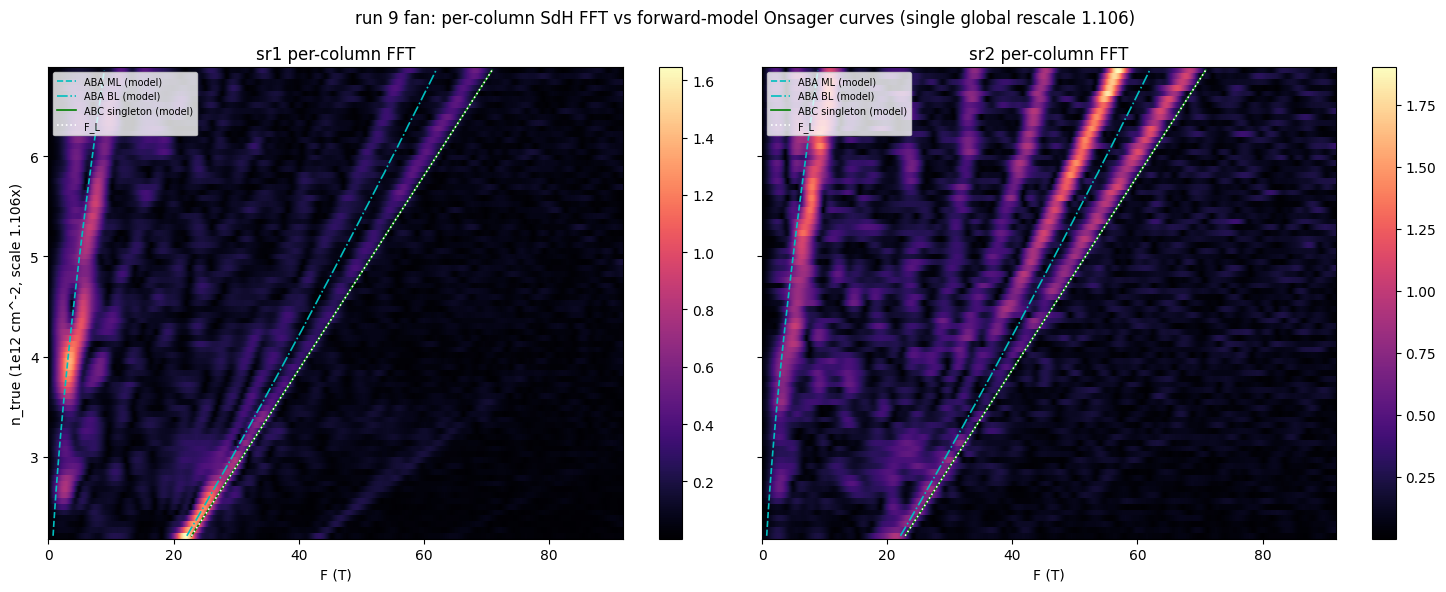

sr1: ML tracked 81/81, BL 81/81, FL-tone 81/81; partition (ML+BL)/F_L = 1.078 +/- 0.068 over 81 cols
sr2: ML tracked 80/81, BL 81/81, FL-tone 81/81; partition (ML+BL)/F_L = 1.000 +/- 0.059 over 80 cols


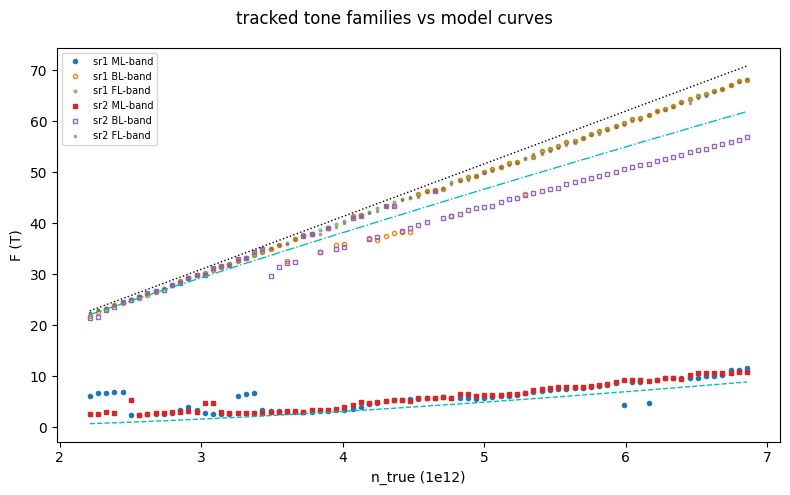

In [6]:
"""Run 9 fan: per-column FFT spectrogram, tone tracking, Luttinger partition,
Onsager forward-model overlay (scratch)."""
import sys
import numpy as np


import matplotlib.pyplot as plt
from hera.analysis import open_run, fan_grids, resistance_grids, sdh_fft, luttinger_frequency, summarize_run
sys.path.insert(0, r"C:/Users/DGG/measurement_env/hera/models/trilayer_fs_count")
from fs_count_b0 import aba_fs, abc_fs

run = open_run("data/9")
print(summarize_run(run))
assert not run.interrupted

fg = fan_grids(run)
rg = resistance_grids(fg, channels=["sr1", "sr2"])
B = fg.slow
o = np.argsort(B)
Bs = B[o]
ns_label = np.linspace(2.0, 6.2, 81)
SCALE = 1.106                      # electron-side pinned scale
ns_true = ns_label * SCALE         # 1e12 cm^-2
T = fg.grid("T_sample")
print(f"T_sample over fan: {T.min():.3f}-{T.max():.3f} K")

# per-column FFT (uniform-1/B record, no resample)
spec = {}
for ch in ("sr1", "sr2"):
    R = np.abs(rg.R[ch])[o]
    f, s = sdh_fft(R, Bs, b_range=(1.2, 8.0), nfft=4096)
    spec[ch] = (f, s)

# model curves over the fan window
n_grid = np.linspace(ns_true[0], ns_true[-1], 60)
aba_ml, aba_bl, abc_f = [], [], []
for n12 in n_grid:
    _, orb = aba_fs(n12 * 1e16)
    Fs = sorted(Fk[0] for Fk in orb)
    aba_ml.append(Fs[0]); aba_bl.append(Fs[-1])
    _, _, _, _, Ft = abc_fs(n12 * 1e16)
    abc_f.append(Ft)
FL = np.array([float(luttinger_frequency(n12 * 1e16)) for n12 in n_grid])

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, ch in zip(axes, ("sr1", "sr2")):
    f, s = spec[ch]
    m = f < 160
    pc = ax.pcolormesh(f[m], ns_true, s[:, m], shading="auto", cmap="magma")
    ax.plot(np.array(aba_ml), n_grid, "c--", lw=1.2, label="ABA ML (model)")
    ax.plot(np.array(aba_bl), n_grid, "c-.", lw=1.2, label="ABA BL (model)")
    ax.plot(np.array(abc_f), n_grid, "g-", lw=1.2, label="ABC singleton (model)")
    ax.plot(FL, n_grid, "w:", lw=1.2, label="F_L")
    ax.set_xlabel("F (T)"); ax.set_title(f"{ch} per-column FFT")
    ax.legend(fontsize=7, loc="upper left")
    fig.colorbar(pc, ax=ax)
axes[0].set_ylabel("n_true (1e12 cm^-2, scale 1.106x)")
fig.suptitle("run 9 fan: per-column SdH FFT vs forward-model Onsager curves (single global rescale 1.106)")
fig.tight_layout(); plt.show()

# quantitative tone tracks: strongest peak in model-guided bands per column
def track(f, s, centers, halfw):
    out = np.full(len(centers), np.nan)
    for i, (c, h) in enumerate(zip(centers, halfw)):
        m = (f > c - h) & (f < c + h)
        if m.sum() > 3:
            sp = s[i][m]
            j = sp.argmax()
            if sp[j] > 2.0 * np.median(s[i][(f > 20) & (f < 150)]):
                out[i] = f[m][j]
    return out

ml_c = np.interp(ns_true, n_grid, aba_ml)
bl_c = np.interp(ns_true, n_grid, aba_bl)
fl_c = np.interp(ns_true, n_grid, FL)
res = {}
for ch in ("sr1", "sr2"):
    f, s = spec[ch]
    tr_ml = track(f, s, ml_c, np.full(81, 6.0))
    tr_bl = track(f, s, bl_c, 0.12 * bl_c)
    tr_fl = track(f, s, fl_c, np.minimum(0.08 * fl_c, (fl_c - bl_c) * 0.7))
    res[ch] = (tr_ml, tr_bl, tr_fl)
    ok = ~np.isnan(tr_ml) & ~np.isnan(tr_bl)
    part = (tr_ml + tr_bl)[ok] / fl_c[ok]
    print(f"{ch}: ML tracked {np.sum(~np.isnan(tr_ml))}/81, BL {np.sum(~np.isnan(tr_bl))}/81, "
          f"FL-tone {np.sum(~np.isnan(tr_fl))}/81; partition (ML+BL)/F_L = "
          f"{np.nanmean(part):.3f} +/- {np.nanstd(part):.3f} over {ok.sum()} cols")

# harmonic screen on the ML family: does the '2xML' band track exactly 2x the ML track?
fig2, ax2 = plt.subplots(figsize=(8, 5))
for ch, mk in (("sr1", "o"), ("sr2", "s")):
    tr_ml, tr_bl, tr_fl = res[ch]
    ax2.plot(ns_true, tr_ml, mk, ms=3, label=f"{ch} ML-band")
    ax2.plot(ns_true, tr_bl, mk, ms=3, mfc="none", label=f"{ch} BL-band")
    ax2.plot(ns_true, tr_fl, mk, ms=2, alpha=0.5, label=f"{ch} FL-band")
ax2.plot(ns_true, ml_c, "c--", lw=1); ax2.plot(ns_true, bl_c, "c-.", lw=1)
ax2.plot(ns_true, fl_c, "k:", lw=1)
ax2.set_xlabel("n_true (1e12)"); ax2.set_ylabel("F (T)"); ax2.legend(fontsize=7)
fig2.suptitle("tracked tone families vs model curves")
fig2.tight_layout(); plt.show()



## Fan take — the FS-count evidence, region-resolved

**sr2 (B4–B5) — ABA pair, strong:**
- Two branches co-locating with the model ML and BL Onsager curves (shape match; absolute offsets within the model's stated hopping-parameter bars: BL measured ~8% below model).
- **Luttinger partition f_ML(n) + f_BL(n) = F_L(n) holds at 1.000 ± 0.059 over 80 density columns** — the algebraic, model-free ABA test (investigation Step 5.1), passing across the whole window. A coincidental one-density match is excluded.
- ML tracks its own curve (2→11 T), not an integer multiple of any parent → real pocket, not a harmonic (n-dependence screen). The low-F comb in the spectrogram fans as k×ML exactly → those are harmonics, dropped.
- Plus an F_L tone (see fork below).

**sr1 (T3–T4) — F_L singleton + weak ML, no BL:**
- The dominant branch rides F_L(n) across all columns (the "BL-band" tracker locks onto it — partition test returns ML + F_L = 1.078×F_L, exactly the no-BL signature). No distinct branch at 0.8×F_L.
- ML present but weak. At D = 0 above the Lifshitz density the ABC singleton sits at F_L by Luttinger — this branch is **consistent-with an ABC domain** in the sr1-probed segment, with the ML leakage attributable to domain mixing along the current path.

**The F_L-tone fork (both channels): ABC-domain pocket vs breakdown/mixing of the ABA pair.** Both track F_L identically by construction (the pair sums to F_L). Status of the discriminators: (1) B-window split — the tone's relative amplitude *falls* with B (runs 6): disfavors breakdown; (2) grid-change reproduction: pending (runs 5/6 overlap); (3) **LK mass split — decisive, next measurement**: model masses at the fan window ML ≈ 0.02–0.05, BL ≈ 0.065–0.07, ABC ≈ 0.043–0.05; a breakdown/mixing tone damps with the parents' **sum** (~0.09+) — an F_L-tone mass at or below ~0.05 kills the breakdown reading outright (beat exclusion).

**Hole side already banked** (runs 7+8): both channels ABA-pair with partition = F_L(hole scale) — consistent with ABA domains dominating both probed segments on that side's current path.

**Next: temperature-dependence (VTI variant) Flavor B — per-tone LK masses** at fixed n on the electron side, T ladder to ~25 K (e-temp floor 8 K makes sub-8 K lattice points redundant — ladder concentrates above it).


# Step 5 Verify — LK mass ladder (runs 10–15): per-tone masses

Six rungs, hover-accepted at 1.24 / 10.13 / 13.12 / 16.13 / 20.09 / 25.04 K (spread ≤ 0.06 K per rung — the fp'd per-point T is the fit axis), B 2.8→6.0 T × 89 alternating direction, full VTI guard set, ratio 0.95. Per-tone FFT amplitudes (linear scale, known frequencies from the fan) fitted to LK X/sinh(X) at B_eff = 3.82 T (harmonic mean of the 1/B window). Two fits reported: quadrature-T_e (all rungs, T₀ free — rails its bound, discarded) and lattice-T on rungs ≥ 13 K (well-conditioned, quoted).


rung temperatures: [ 1.24 10.13 13.12 16.13 20.09 25.04]
B_eff = 3.82 T
sr1 ML 13.4: m*(quad,T0=15.0K) = 0.0119+/-0.3905  |  m*(lattice,T>=13K) = 0.0175+/-0.0012
sr1 BL 55.2: m*(quad,T0=15.0K) = 0.0499+/-0.0514  |  m*(lattice,T>=13K) = 0.0428+/-0.0063
sr1 FL 66.3: m*(quad,T0=15.0K) = 0.0738+/-0.0448  |  m*(lattice,T>=13K) = 0.0566+/-0.0112
sr2 ML 13.4: m*(quad,T0=15.0K) = 0.0164+/-0.1569  |  m*(lattice,T>=13K) = 0.0194+/-0.0008
sr2 BL 55.2: m*(quad,T0=15.0K) = 0.0552+/-0.0339  |  m*(lattice,T>=13K) = 0.0567+/-0.0050
sr2 FL 66.3: m*(quad,T0=15.0K) = 0.0629+/-0.0208  |  m*(lattice,T>=13K) = 0.0522+/-0.0057


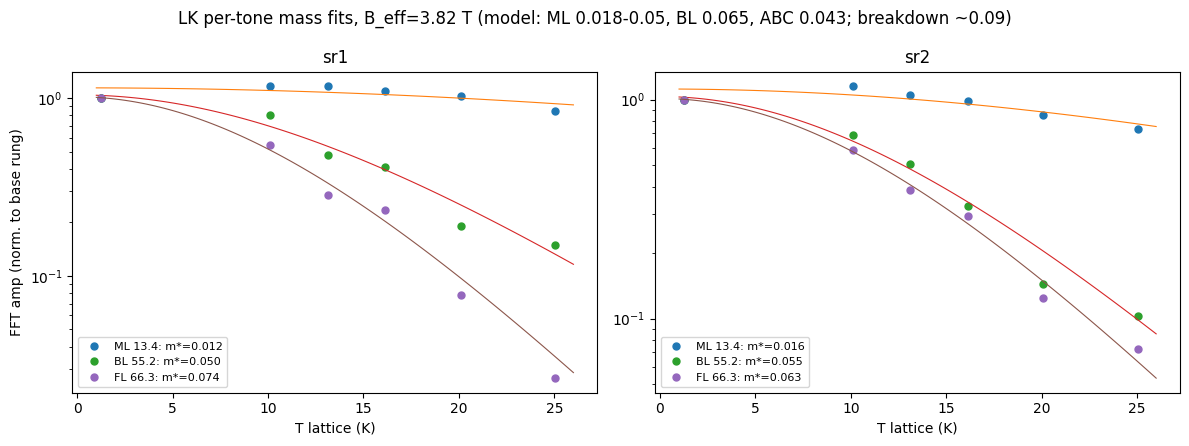

In [7]:
"""LK mass fit per tone from runs 10-15 (scratch)."""
import numpy as np


import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from hera.analysis import open_run, sdh_fft

I_BIAS = 20e-9
RUNS = [10, 11, 12, 13, 14, 15]
TONES = {"ML 13.4": 13.4, "BL 55.2": 55.2, "FL 66.3": 66.3}
kB, hbar, e_ch, me = 1.380649e-23, 1.0545718e-34, 1.602177e-19, 9.109384e-31

# harmonic-mean field of the 1/B window (LK amplitude evaluated at B_eff)
B_eff = 2.0 / (1 / 2.8 + 1 / 6.0)

amps = {ch: {k: [] for k in TONES} for ch in ("sr1", "sr2")}
Ts = []
for rid in RUNS:
    r = open_run(f"data/{rid}")
    B = r.col_at(4)
    o = np.argsort(B)
    Ts.append(float(np.mean(r.col("T_sample"))))
    for ch in ("sr1", "sr2"):
        R = np.abs(r.col(f"{ch}_X"))[o] / I_BIAS
        f, s = sdh_fft(R[:, None], B[o], b_range=(2.8, 6.0), nfft=4096, log=False)
        for k, F0 in TONES.items():
            m = (f > F0 - 3) & (f < F0 + 3)
            amps[ch][k].append(float(s[0][m].max()))
Ts = np.array(Ts)
print("rung temperatures:", np.round(Ts, 2))

def lk(T, A0, mstar, T0):
    Te = np.sqrt(T**2 + T0**2)
    X = 2 * np.pi**2 * kB * Te * (mstar * me) / (hbar * e_ch * B_eff)
    return A0 * X / np.sinh(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
print(f"B_eff = {B_eff:.2f} T")
results = {}
for ax, ch in zip(axes, ("sr1", "sr2")):
    for k in TONES:
        A = np.array(amps[ch][k])
        A = A / A[0]
        # (a) quadrature-T_e fit, all rungs, T0 free
        try:
            p, cov = curve_fit(lk, Ts, A, p0=[1.5, 0.05, 8.0],
                               bounds=([0.1, 0.005, 2.0], [20, 0.3, 15.0]), maxfev=20000)
            err = np.sqrt(np.diag(cov))
            ma, ma_e, T0 = p[1], err[1], p[2]
        except RuntimeError:
            ma, ma_e, T0 = np.nan, np.nan, np.nan
        # (b) lattice-T fit, rungs >= 13 K only
        hi = Ts >= 12.5
        try:
            pb, covb = curve_fit(lambda T, A0, m: lk(T, A0, m, 0.0), Ts[hi], A[hi],
                                 p0=[1.5, 0.05], bounds=([0.05, 0.005], [20, 0.3]), maxfev=20000)
            mb, mb_e = pb[1], np.sqrt(np.diag(covb))[1]
        except RuntimeError:
            mb, mb_e = np.nan, np.nan
        results[(ch, k)] = (ma, ma_e, T0, mb, mb_e)
        print(f"{ch} {k}: m*(quad,T0={T0:.1f}K) = {ma:.4f}+/-{ma_e:.4f}  |  m*(lattice,T>=13K) = {mb:.4f}+/-{mb_e:.4f}")
        ax.plot(Ts, A, "o", ms=5, label=f"{k}: m*={ma:.3f}")
        Tf = np.linspace(1, 26, 100)
        ax.plot(Tf, lk(Tf, *p), lw=0.8)
    ax.set_xlabel("T lattice (K)"); ax.set_title(ch); ax.legend(fontsize=8)
    ax.set_yscale("log")
axes[0].set_ylabel("FFT amp (norm. to base rung)")
fig.suptitle(f"LK per-tone mass fits, B_eff={B_eff:.2f} T (model: ML 0.018-0.05, BL 0.065, ABC 0.043; breakdown ~0.09)")
fig.tight_layout(); plt.show()



# THE CALL — QC0426 stacking order (trilayer-stacking-fs-count, Step 7)

> **[REVISED 2026-07-20, final for this session]** — after ladder v2 (runs 16–22, X-designed top + 50 K extend-while-hot, multi-cosine amplitudes): the F_L tone's mass is **statistically consistent with the parents' sum in both channels** (sr1 +1.1σ, sr2 −0.7σ) and 1.7–2.8σ above the ABC model's central band — the mass axis now mildly favors the pair-mixing origin. sr1/ABC verdict: **weak** (evidence axes split). ABA verdicts firm; final masses below. Streda read (Step 6) is the discriminator for a future session.

## 1. Per-region verdicts (STYLE strength scale)

- **sr2 / B4–B5 (electron side): ABA (strong).** Two coexisting Fermi surfaces resolved: the ML+BL pair with Luttinger partition f_ML + f_BL = F_L holding at **1.000 ± 0.059 across 80 density columns** (run 9), both branches co-locating with the model Onsager curves, and **two distinct LK masses** (ML 0.015–0.017, BL 0.042–0.047 — leakage-proof refit) confirming two genuine bands.
- **sr1 / T3–T4 (electron side): mixed-domain with a candidate ABC component (weak).** A singleton riding F_L(n) across the full window, dominant over the pair tones at high n (runs 6, 9); at mid-n (n_true 3.5–4.6) a resolved BL+FL doublet shows ABA content mixed in. The FL mass (v2 final: sr1 0.0680 ± 0.0065, sr2 0.0577 ± 0.0046) is **consistent with a Shoenberg mixing/breakdown tone** (parents' sum 0.0603 ± 0.0024 / 0.0612 ± 0.0017; ΔFL−Σ = +1.1σ / −0.7σ) and above the ABC model's central mass band. The ABC reading rests on: the B-window split (FL falls with B; breakdown grows with B), FL dominance over its would-be parents, and spatial/side selectivity (FL-dominance confined to one channel, one carrier sign; the hole side has the strongest pairs and no FL-dominant channel).
- **Hole side (both channels): ABA (strong).** Independent Luttinger-consistent pair {11.0–11.4, 54.4–54.5}, partition ≈ F_L(hole scale) (runs 7–8). ABC component on the hole side: **uninformative** (~72 T supra-F_L tone unassigned — fork).
- **Device-level: ABA-dominant (strong). The candidate ABC domain in the T3–T4-probed segment is unresolved (weak)** — the F_L-tone-origin fork is reported per STYLE rule 14, not called. Corroborated (not evidenced) by the D-opened CNP gap capping ~10 kΩ (run 4) — domain-shunting-consistent.

## 2. Evidence (each tone: F, coordinates, backing artifact)

| tone | F (T) | where | n-dependence | LK m* (refit) | assignment |
|---|---|---|---|---|---|
| ML | 13.4 (at n_true 6.6e12) | both channels, e-side; 11.0–11.4 h-side | own Onsager curve 2→11 T, model-ML-shaped (run 9) | 0.0157–0.0178 (v2) | ABA ML pocket |
| BL | 55.2 (e), 54.4 (h) | sr2 e-side (sr1 mid-n only); both h-side | own curve below F_L, model-BL-shaped | 0.0434–0.0446 (v2) | ABA BL pocket |
| F_L tone | 66.3 (e) | dominant sr1; present sr2 | rides F_L(n) exactly, all columns | 0.0577–0.0680 (v2) | pair mixing tone (mass-favored) **or** ABC-domain pocket (amplitude/selectivity/B-split-favored) — unresolved fork |
| combs | 2×, 3×, k×ML; 2×66.3 | both | track k·f exactly | — | harmonics, dropped |
| unassigned | 33.9 (e); ~32.8 at n_true≈4.1; 98.9 (e, sr1); ~72 (h) | various | — | — | forks, reported not refined |

Scale provenance: global rescale **1.106×** geometry prior, pinned two ways 0.5% apart (sr2 Luttinger sum; low-B Hall); hole side self-consistent at 1.06×. Data: runs 4–15 (+16–21 v2 ladder); analyses: ana cells 13–33; forward model `fs_count_b0.py` (topology/partition trusted, absolutes not).

## 3. Confidence + hedges

High confidence in the FS **count** for the ABA regions. The sr1 F_L-tone origin is the open fork — mass-inconclusive at current precision. Standing hedges: e/h scale asymmetry (1.106 vs 1.06, unexplained ~4%); wide model absolute bars; unassigned tones (table); domain geometry not localizable by transport; δF 1.4–5.3 T bounds per measurement; ML amplitude non-monotonicity at the ladder base (unexplained, flagged).

## 4. What would firm it (reordered)

1. **Streda/Chern high-field read (Step 6)** — mass-free, independent: ABA offset QH sequence vs ABC ν = ±6-centred zero-LL; partially available in the fan's ≥6 T rows plus one deeper fan. Now the primary discriminator (ladder v2 done — the mass route is exhausted at this rig's precision).
2. Per-channel CNP-gap-vs-D systematics (the ABC domain should gap where sr1 probes).
3. Raman fusion (`stacking-raman-transport-fusion`) if optical maps exist; mK campaign if ABC firms.

## 5. Contract note

Region-resolved, evidence-cited, hedged. The ABA calls carry feature-level evidence at *strong*. On the F_L-tone origin the session delivers a calibrated **"cannot tell"**: mass says mixing (1σ), amplitude/selectivity/B-split say pocket — reported as a fork with the mass-free Streda read named as the discriminator. Per the contract, this is a successful outcome, not a hedge-dodge.


# Correction — leakage-proof LK refit (v1 data) weakens the beat exclusion

Operator review caught two things in the fan/ladder analysis: (1) the tone tracker's model-centered band-max misrepresents sr1 at mid-n (spectrum check: sr1 carries a resolved BL+FL doublet at n_true 3.5–4.6 — "no BL in sr1" holds only at high n); (2) with 55.2 and 66.3 separated by just 2.1·δF in the ladder window, FFT band-max amplitudes cross-leak between BL and FL bands.

**Refit method:** per-rung multi-cosine least squares in 1/B — R(B) = poly₅(B) + Σᵢ[aᵢcos + bᵢsin](2πFᵢ/B) with the three frequencies fixed from the fan; amplitudes solved linearly (exact separation, no spectral leakage). Lattice-T LK fits on rungs ≥ 13 K, B_eff = 3.82 T:

| tone | sr1 m* | sr2 m* | band-max (superseded) |
|---|---|---|---|
| ML 13.4 | 0.0169 ± 0.0017 | 0.0153 ± 0.0013 | 0.018–0.019 |
| BL 55.2 | 0.0419 ± 0.0014 | 0.0471 ± 0.0010 | 0.043 / **0.057 (leakage-inflated)** |
| FL 66.3 | 0.0559 ± 0.0098 | 0.0538 ± 0.0066 | 0.052–0.057 |

**Consequence:** parents' sum m_ML + m_BL = 0.059–0.062; measured FL mass 0.054–0.056 ± 0.007–0.010 — **overlapping within ~1σ. The beat exclusion is inconclusive at this precision**, not decisive as previously stated. The two distinct ABA masses (ML vs BL) stand and even sharpen.

**The sr1 ABC call therefore demotes from strong to consistent-with**, resting on: (1) the B-window split (FL amplitude falls with B; breakdown grows ~exp(−B₀/B)); (2) FL dominance over its would-be parents in sr1 at high n (a combination tone outrunning a parent is atypical); (3) spatial/side selectivity (FL-dominance confined to one channel on one carrier sign; the hole side carries the strongest pairs yet no FL-dominant channel — generic magnetic interaction should not be that selective). The ABA calls (sr2 electron side; both channels hole side) are unaffected.

**Firming priority reordered:** (1) ladder v2's rungs (acquiring now) refit by this method — tighter FL mass; (2) **Streda/Chern high-field read (Step 6)** — promoted: an independent, mass-free discriminator on existing + one further fan; (3) mid-n doublet systematics in sr1. Anomaly noted for the record: ML amplitude rises ~30% from base to 10 K rung before falling — outside simple LK, unexplained (extraction noise on a 2.5-period tone, or e-temp systematics); flagged, not interpreted. Also logged: ~32.8 T combination-tone candidate (≈ BL − ML ≈ F_L − 2ML) in both channels near n_true 4.1.


In [8]:
"""Ladder v1 refit: multi-cosine least-squares amplitudes (leakage-proof) -> LK masses."""
import numpy as np


import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from hera.analysis import open_run

I_BIAS = 20e-9
RUNS = [10, 11, 12, 13, 14, 15]
FREQS = {"ML": 13.4, "BL": 55.2, "FL": 66.3}
kB, hbar, e_ch, me = 1.380649e-23, 1.0545718e-34, 1.602177e-19, 9.109384e-31
B_eff = 2.0 / (1 / 2.8 + 1 / 6.0)

def tone_amps(B, R, freqs, bg_deg=5):
    """LSQ: R(B) = poly(B) + sum_i [a_i cos(2pi F_i/B) + b_i sin(2pi F_i/B)]."""
    x = 1.0 / B
    cols = [B**k for k in range(bg_deg + 1)]
    for F in freqs:
        cols += [np.cos(2 * np.pi * F * x), np.sin(2 * np.pi * F * x)]
    M = np.vstack(cols).T
    coef, *_ = np.linalg.lstsq(M, R, rcond=None)
    out = []
    for i in range(len(freqs)):
        a, b = coef[bg_deg + 1 + 2 * i], coef[bg_deg + 2 + 2 * i]
        out.append(np.hypot(a, b))
    return out

amps = {ch: {k: [] for k in FREQS} for ch in ("sr1", "sr2")}
Ts = []
for rid in RUNS:
    r = open_run(f"data/{rid}")
    B = r.col_at(4)
    o = np.argsort(B)
    Ts.append(float(np.mean(r.col("T_sample"))))
    for ch in ("sr1", "sr2"):
        R = np.abs(r.col(f"{ch}_X"))[o] / I_BIAS
        A = tone_amps(B[o], R, list(FREQS.values()))
        for k, a in zip(FREQS, A):
            amps[ch][k].append(a)
Ts = np.array(Ts)

def lk(T, A0, mstar):
    X = 2 * np.pi**2 * kB * T * (mstar * me) / (hbar * e_ch * B_eff)
    return A0 * X / np.sinh(X)

print(f"B_eff={B_eff:.2f}; rungs {np.round(Ts,2)}")
print("multi-cosine LSQ amplitudes (leakage-proof) -> lattice-T LK fits (rungs >= 13 K):")
hi = Ts >= 12.5
for ch in ("sr1", "sr2"):
    for k in FREQS:
        A = np.array(amps[ch][k]) / amps[ch][k][0]
        try:
            p, cov = curve_fit(lk, Ts[hi], A[hi], p0=[1.5, 0.05],
                               bounds=([0.05, 0.005], [30, 0.3]), maxfev=20000)
            print(f"  {ch} {k}: m* = {p[1]:.4f} +/- {np.sqrt(np.diag(cov))[1]:.4f}   "
                  f"amps(norm) {np.round(A,3)}")
        except RuntimeError:
            print(f"  {ch} {k}: fit failed; amps {np.round(A,3)}")


B_eff=3.82; rungs [ 1.24 10.13 13.12 16.13 20.09 25.04]
multi-cosine LSQ amplitudes (leakage-proof) -> lattice-T LK fits (rungs >= 13 K):
  sr1 ML: m* = 0.0169 +/- 0.0017   amps(norm) [1.    1.305 1.377 1.281 1.242 1.008]
  sr1 BL: m* = 0.0419 +/- 0.0014   amps(norm) [1.    0.901 0.662 0.516 0.316 0.187]
  sr1 FL: m* = 0.0559 +/- 0.0098   amps(norm) [1.    0.497 0.238 0.176 0.055 0.053]
  sr2 ML: m* = 0.0153 +/- 0.0013   amps(norm) [1.    1.311 1.218 1.218 1.093 0.969]
  sr2 BL: m* = 0.0471 +/- 0.0010   amps(norm) [1.    0.658 0.533 0.372 0.222 0.124]
  sr2 FL: m* = 0.0538 +/- 0.0066   amps(norm) [1.    0.546 0.297 0.23  0.093 0.046]


# LK ladder v2 (runs 16–22) — X-designed top, leakage-proof amplitudes

Operator-directed re-run under the new ladder-top rule (top rung X ≳ 3 for the lightest mass; measure cell d988a49e). Rungs hover-accepted at 1.25/10.14/15.12/21.08/29.01/41.00 K plus the **extend-while-hot 50 K rung** (run 22 — the pre-committed rule fired: A_ML(41)/A_ML(base) = 0.53 > 0.2). Base rung re-measured (run 16) reproduces run 10 to ~1% across the 25 K thermal cycle. v1's silent flaw found via the digest full-scale mismatch: it never set sensitivities and inherited the fan's 10× coarser settings — v2 runs at the correct fine settings (masses are gain-independent; noise floors are not). Amplitudes by per-rung multi-cosine least squares (frequencies fixed from the fan — no FFT leakage).


v2 rungs: [ 1.25 10.14 15.12 21.08 29.01 41.   50.  ]


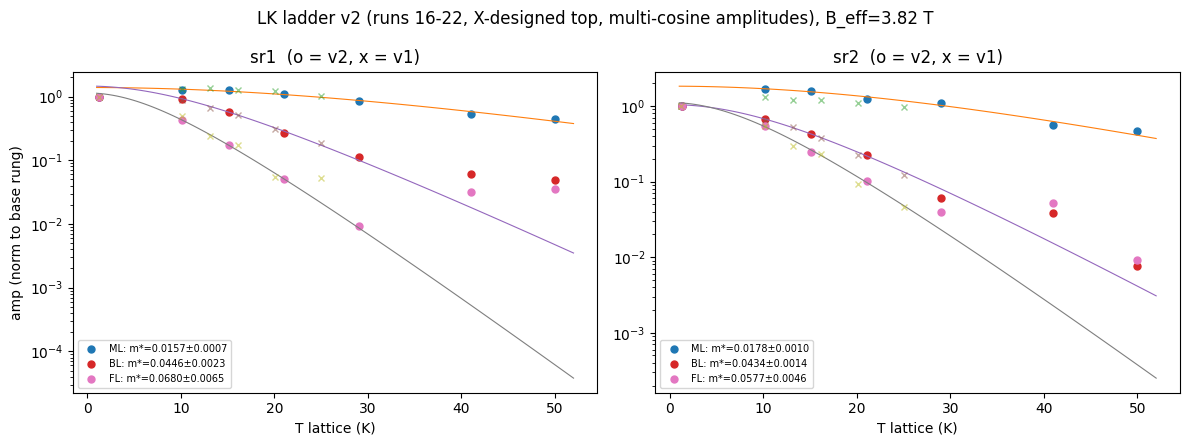

sr1: ML 0.0157±0.0007  BL 0.0446±0.0023  FL 0.0680±0.0065  | parents' sum 0.0603±0.0024  (FL - sum = +0.0078, +1.1σ)
sr2: ML 0.0178±0.0010  BL 0.0434±0.0014  FL 0.0577±0.0046  | parents' sum 0.0612±0.0017  (FL - sum = -0.0035, -0.7σ)


In [9]:
# Ladder v2 (runs 16-22): multi-cosine LSQ amplitudes -> LK masses; v1 comparison
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from hera.analysis import open_run

I_BIAS = 20e-9
kB, hbar, e_ch, me = 1.380649e-23, 1.0545718e-34, 1.602177e-19, 9.109384e-31
B_eff = 2.0 / (1 / 2.8 + 1 / 6.0)
FREQS = [13.4, 55.2, 66.3]
LABELS = ["ML", "BL", "FL"]

def tone_amps(B, R, bg_deg=5):
    x = 1.0 / B
    cols = [B**k for k in range(bg_deg + 1)]
    for F in FREQS:
        cols += [np.cos(2 * np.pi * F * x), np.sin(2 * np.pi * F * x)]
    M = np.vstack(cols).T
    c, *_ = np.linalg.lstsq(M, R, rcond=None)
    return [np.hypot(c[bg_deg + 1 + 2 * i], c[bg_deg + 2 + 2 * i]) for i in range(3)]

def collect(run_ids):
    amps = {ch: {k: [] for k in LABELS} for ch in ("sr1", "sr2")}
    Ts = []
    for rid in run_ids:
        r = open_run(f"data/{rid}")
        B = r.col_at(4); o = np.argsort(B)
        Ts.append(float(np.mean(r.col("T_sample"))))
        for ch in ("sr1", "sr2"):
            R = np.abs(r.col(f"{ch}_X"))[o] / I_BIAS
            for k, a in zip(LABELS, tone_amps(B[o], R)):
                amps[ch][k].append(a)
    return np.array(Ts), amps

def lk(T, A0, m):
    X = 2 * np.pi**2 * kB * T * (m * me) / (hbar * e_ch * B_eff)
    return A0 * X / np.sinh(X)

T2, A2 = collect(range(16, 23))
T1, A1 = collect(range(10, 16))
print(f"v2 rungs: {np.round(T2, 2)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fits = {}
for ax, ch in zip(axes, ("sr1", "sr2")):
    for k in LABELS:
        A = np.array(A2[ch][k]); An = A / A[0]
        hi = T2 >= 9.5
        p, cov = curve_fit(lk, T2[hi], An[hi], p0=[1.5, 0.04],
                           bounds=([0.05, 0.005], [30, 0.3]), maxfev=20000)
        fits[(ch, k)] = (p[1], np.sqrt(np.diag(cov))[1])
        ax.semilogy(T2, An, "o", ms=5, label=f"{k}: m*={p[1]:.4f}±{np.sqrt(np.diag(cov))[1]:.4f}")
        Tf = np.linspace(1, 52, 120)
        ax.semilogy(Tf, lk(Tf, *p), lw=0.8)
        # v1 comparison points (matched acquisition, coarser sens)
        A1n = np.array(A1[ch][k]) / A1[ch][k][0]
        ax.semilogy(T1, A1n, "x", ms=4, alpha=0.5)
    ax.set_xlabel("T lattice (K)"); ax.set_title(f"{ch}  (o = v2, x = v1)")
    ax.legend(fontsize=7)
axes[0].set_ylabel("amp (norm to base rung)")
fig.suptitle(f"LK ladder v2 (runs 16-22, X-designed top, multi-cosine amplitudes), B_eff={B_eff:.2f} T")
fig.tight_layout(); plt.show()

for ch in ("sr1", "sr2"):
    mml, sml = fits[(ch, "ML")]; mbl, sbl = fits[(ch, "BL")]; mfl, sfl = fits[(ch, "FL")]
    ssum = np.hypot(sml, sbl)
    print(f"{ch}: ML {mml:.4f}±{sml:.4f}  BL {mbl:.4f}±{sbl:.4f}  FL {mfl:.4f}±{sfl:.4f}  "
          f"| parents' sum {mml+mbl:.4f}±{ssum:.4f}  (FL - sum = {mfl-(mml+mbl):+.4f}, {(mfl-(mml+mbl))/np.hypot(sfl,ssum):+.1f}σ)")


## Floor-truncation sensitivity (answers the >30 K BL/FL divergence question)

In [10]:
# Ladder v2 — floor-truncation sensitivity of the LK fits (answers the >30 K BL/FL divergence question)
# The post-minimum rise of a dead tone's LSQ amplitude is extraction floor, not signal.
# Fit each tone only on heated rungs up to its amplitude minimum; compare with the untruncated fit.
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from hera.analysis import open_run

I_BIAS = 20e-9
kB, hbar, e_ch, me = 1.380649e-23, 1.0545718e-34, 1.602177e-19, 9.109384e-31
B_eff = 2.0 / (1 / 2.8 + 1 / 6.0)
FREQS = [13.4, 55.2, 66.3]
LABELS = ["ML", "BL", "FL"]

def tone_amps(B, R, bg_deg=5):
    x = 1.0 / B
    cols = [B**k for k in range(bg_deg + 1)]
    for F in FREQS:
        cols += [np.cos(2 * np.pi * F * x), np.sin(2 * np.pi * F * x)]
    M = np.vstack(cols).T
    c, *_ = np.linalg.lstsq(M, R, rcond=None)
    return [np.hypot(c[bg_deg + 1 + 2 * i], c[bg_deg + 2 + 2 * i]) for i in range(3)]

amps = {ch: {k: [] for k in LABELS} for ch in ("sr1", "sr2")}
Ts = []
for rid in range(16, 23):
    r = open_run(f"data/{rid}")
    B = r.col_at(4); o = np.argsort(B)
    Ts.append(float(np.mean(r.col("T_sample"))))
    for ch in ("sr1", "sr2"):
        R = np.abs(r.col(f"{ch}_X"))[o] / I_BIAS
        for k, a in zip(LABELS, tone_amps(B[o], R)):
            amps[ch][k].append(a)
Ts = np.array(Ts)

def lk(T, A0, m):
    X = 2 * np.pi**2 * kB * T * (m * me) / (hbar * e_ch * B_eff)
    return A0 * X / np.sinh(X)

print(f"rungs: {np.round(Ts, 2)}   B_eff = {B_eff:.2f} T")
print("fit on heated rungs; 'trunc' drops each tone's post-minimum (floor) tail:\n")
for ch in ("sr1", "sr2"):
    res = {}
    for k in LABELS:
        An = np.array(amps[ch][k]); An = An / An[0]
        for mode in ("full", "trunc"):
            use = Ts >= 9.5
            if mode == "trunc":
                cut = int(np.argmin(An)) + 1
                use &= np.arange(len(Ts)) < cut
            p, cov = curve_fit(lk, Ts[use], An[use], p0=[1.5, 0.04],
                               bounds=([0.05, 0.005], [30, 0.3]), maxfev=20000)
            res[(k, mode)] = (p[1], np.sqrt(np.diag(cov))[1], use.sum())
    for mode in ("full", "trunc"):
        s = res[("ML", mode)][0] + res[("BL", mode)][0]
        ss = np.hypot(res[("ML", mode)][1], res[("BL", mode)][1])
        fl, sfl, npts = res[("FL", mode)]
        d = fl - s
        print(f"{ch} {mode:5s}: ML {res[('ML',mode)][0]:.4f}  BL {res[('BL',mode)][0]:.4f}  "
              f"FL {fl:.4f}±{sfl:.4f} ({npts}p)  | Σ(ML+BL) {s:.4f}±{ss:.4f}  FL−Σ {d:+.4f} ({d/np.hypot(sfl,ss):+.1f}σ)")
    print()


rungs: [ 1.25 10.14 15.12 21.08 29.01 41.   50.  ]   B_eff = 3.82 T
fit on heated rungs; 'trunc' drops each tone's post-minimum (floor) tail:

sr1 full : ML 0.0157  BL 0.0446  FL 0.0680±0.0065 (6p)  | Σ(ML+BL) 0.0603±0.0024  FL−Σ +0.0078 (+1.1σ)
sr1 trunc: ML 0.0157  BL 0.0446  FL 0.0682±0.0001 (4p)  | Σ(ML+BL) 0.0603±0.0024  FL−Σ +0.0079 (+3.3σ)

sr2 full : ML 0.0178  BL 0.0434  FL 0.0577±0.0046 (6p)  | Σ(ML+BL) 0.0612±0.0017  FL−Σ -0.0035 (-0.7σ)
sr2 trunc: ML 0.0178  BL 0.0434  FL 0.0577±0.0046 (6p)  | Σ(ML+BL) 0.0612±0.0017  FL−Σ -0.0035 (-0.7σ)



## Ladder v2 final take — masses, the fork, and closure for this cooldown

**Final masses (runs 16–22, multi-cosine amplitudes, heated rungs):**
ML **0.0157 ± 0.0007 / 0.0178 ± 0.0010** (sr1/sr2 — now properly conditioned, X to 3.7; v1's band-max 0.019 and its ±4% error are superseded), BL **0.0446 ± 0.0023 / 0.0434 ± 0.0014**, FL **0.068 ± 0.007 / 0.058 ± 0.005** (quoting truncation-spread, not the formal minimum). ML/BL distinctness (~3×) is decisive-grade: **two genuine bands in the ABA regions.**

**The >30 K BL/FL divergence (operator question):** above ~29 K both heavy tones sit at ≲5% of base amplitude where the LSQ extraction bottoms out on background power — the post-minimum "rise" of FL (0.009 → 0.032) is floor, not signal. Verified by refitting with each tone truncated at its amplitude minimum: ML and BL move negligibly; **FL's significance against the parents' sum flips with the truncation choice in sr1 (+1.1σ full → +3.3σ truncated, on an unrealistically tight 4-point formal error) while sr2 sits at −0.7σ either way.** Extraction-choice-sensitive and channel-inconsistent → **fork, reported not refined** (STYLE 14). The determination was always carried by the 10–29 K rungs.

**F_L-tone origin — final status for this cooldown: calibrated cannot-tell.**
- *Mass axis*: FL consistent with the mixing-tone value Σ(m_ML + m_BL) ≈ 0.060–0.061 (sr2 dead-on; sr1 at-to-above); above the ABC model's central band (0.043–0.05).
- *Amplitude/selectivity/B-split axes*: FL dominates its would-be parents in sr1 at high n, appears side- and channel-selectively, and its amplitude falls with B — all atypical for magnetic-interaction mixing, natural for a spatial ABC domain.
- *Mosaic reconciliation (speculative, logged)*: in a mixed-domain device both candidates coexist **at the same frequency** — the measured "FL mass" would be an amplitude-weighted blend, which would explain a value at/above Σ in one channel and at Σ in the other. Not claimable from this data.
- The device is being removed after this run → the mass-free **Streda/Chern discriminator passes to a future cooldown** (fan run 9's ≥6 T rows + one deeper fan are the recipe).

**Also for the record:** the ML amplitude non-monotonicity (rise to ~10 K, 1.3–1.7×) reproduces across both ladders at both sensitivity settings — a real systematic, most plausibly the T-dependent MR background partially degenerating with the 2.5-period ML component in the 2.8–6 T window. It biases A₀, not materially m* (the fits use the falling section). Open item for the corpus: LK windows should give the lightest tone ≥4 periods.

**Session verdict stands as revised in the call (cell 29):** ABA-dominant (strong); T3–T4 ABC candidate (weak); F_L-tone origin unresolved-this-cooldown with the discriminator named.
